# Exploración de modelos de clasificación
## Dataset: Breast Cancer Wisconsin (Diagnostic)

**Objetivo:** predecir el diagnóstico de un tumor de mama (`diagnosis`: **M** = maligno, **B** = benigno) a partir de 30 medidas de los núcleos celulares, obtenidas de imágenes digitalizadas de una punción con aguja fina (PAAF).

**Por qué este dataset:** las clases están desbalanceadas (≈63 % benignos / 37 % malignos), así que hay que pensar con cuidado la validación y las métricas. Además, los dos tipos de error no cuestan lo mismo: un **falso negativo** (decir benigno a un tumor maligno) es mucho más grave que un falso positivo.

**Estructura del notebook**
1. Carga de datos
2. Limpieza
3. Análisis exploratorio (EDA)
4. Preparación y estrategia de validación
5. Modelos: Regresión logística, KNN, Árbol de decisión, Bosque aleatorio
6. Evaluación final en el conjunto de prueba
7. Análisis de errores
8. Conclusiones
9. Uso de LLMs

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, GridSearchCV, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

## 1. Carga de datos

Se usa el archivo `data.csv` descargado de Kaggle (*uciml/breast-cancer-wisconsin-data*). Si el archivo no está en la carpeta del notebook, se usa como respaldo la **misma base WDBC (569 casos)** que trae scikit-learn, renombrando las columnas al formato de Kaggle para que el resto del código funcione igual.

In [2]:
RUTA = Path("data.csv")

if RUTA.exists():
    df_raw = pd.read_csv(RUTA)
    origen = "Kaggle (data.csv)"
else:
    bc = load_breast_cancer(as_frame=True)
    def a_formato_kaggle(nombre):
        for prefijo, sufijo in [("mean ", "_mean"), ("worst ", "_worst")]:
            if nombre.startswith(prefijo):
                base = nombre[len(prefijo):]
                break
        else:
            base, sufijo = nombre.replace(" error", ""), "_se"
        base = base.replace("fractal dimension", "fractal_dimension")
        return base + sufijo
    X_tmp = bc.data.rename(columns=a_formato_kaggle)
    diag = bc.target.map({0: "M", 1: "B"}).rename("diagnosis")   # en sklearn 0 = maligno
    df_raw = pd.concat([diag, X_tmp], axis=1)
    origen = "scikit-learn (respaldo, misma base WDBC)"

print("Origen de los datos:", origen)
print("Dimensiones:", df_raw.shape)
df_raw.head()

Origen de los datos: scikit-learn (respaldo, misma base WDBC)
Dimensiones: (569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.990,10.380,122.800,1001.000,0.118,0.278,0.300,0.147,0.242,0.079,1.095,0.905,8.589,153.400,0.006,0.049,0.054,0.016,0.030,0.006,25.380,17.330,184.600,2019.000,0.162,0.666,0.712,0.265,0.460,0.119
1,M,20.570,17.770,132.900,1326.000,0.085,0.079,0.087,0.070,0.181,0.057,0.543,0.734,3.398,74.080,0.005,0.013,0.019,0.013,0.014,0.004,24.990,23.410,158.800,1956.000,0.124,0.187,0.242,0.186,0.275,0.089
2,M,19.690,21.250,130.000,1203.000,0.110,0.160,0.197,0.128,0.207,0.060,0.746,0.787,4.585,94.030,0.006,0.040,0.038,0.021,0.022,0.005,23.570,25.530,152.500,1709.000,0.144,0.424,0.450,0.243,0.361,0.088
3,M,11.420,20.380,77.580,386.100,0.142,0.284,0.241,0.105,0.260,0.097,0.496,1.156,3.445,27.230,0.009,0.075,0.057,0.019,0.060,0.009,14.910,26.500,98.870,567.700,0.210,0.866,0.687,0.258,0.664,0.173
4,M,20.290,14.340,135.100,1297.000,0.100,0.133,0.198,0.104,0.181,0.059,0.757,0.781,5.438,94.440,0.011,0.025,0.057,0.019,0.018,0.005,22.540,16.670,152.200,1575.000,0.137,0.205,0.400,0.163,0.236,0.077


## 2. Limpieza

### 2.1 Tipos de datos, faltantes y columnas vacías

In [3]:
resumen = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "faltantes": df_raw.isna().sum(),
    "% faltantes": (df_raw.isna().mean() * 100).round(1),
    "valores únicos": df_raw.nunique()
})
print(resumen["tipo"].value_counts().to_string())
resumen[resumen["faltantes"] > 0] if resumen["faltantes"].sum() > 0 else print("No hay valores faltantes en ninguna columna.")

tipo
float64    30
str         1
No hay valores faltantes en ninguna columna.


In [4]:
df = df_raw.copy()

# a) Columnas totalmente vacías (en el CSV de Kaggle aparece 'Unnamed: 32' por una coma final en cada fila)
vacias = df.columns[df.isna().all()].tolist()
df = df.drop(columns=vacias)

# b) Identificador: no describe al tumor, solo al registro -> no debe entrar al modelo
ids = [c for c in ["id"] if c in df.columns]
if ids:
    print("¿Hay id repetidos?:", df["id"].duplicated().any())
df = df.drop(columns=ids)

print("Columnas vacías eliminadas:", vacias or "ninguna")
print("Identificadores eliminados:", ids or "ninguno")
print("Dimensiones tras la limpieza de columnas:", df.shape)

Columnas vacías eliminadas: ninguna
Identificadores eliminados: ninguno
Dimensiones tras la limpieza de columnas: (569, 31)


### 2.2 Etiquetas, duplicados y valores imposibles

In [5]:
print("Etiquetas presentes:", sorted(df["diagnosis"].unique()))
assert set(df["diagnosis"].unique()) == {"M", "B"}, "Hay etiquetas inesperadas"

features = [c for c in df.columns if c != "diagnosis"]
print("Número de variables predictoras:", len(features))
print("Filas duplicadas (todas las columnas):", df.duplicated().sum())
print("Filas con mismas medidas pero distinta etiqueta:", df.duplicated(subset=features).sum() - df.duplicated().sum())

negativos = (df[features] < 0).sum()
print("Valores negativos (imposibles en medidas físicas):", int(negativos.sum()))
ceros = (df[features] == 0).sum()
print("Columnas con ceros:", ceros[ceros > 0].to_dict())

Etiquetas presentes: ['B', 'M']
Número de variables predictoras: 30
Filas duplicadas (todas las columnas): 0
Filas con mismas medidas pero distinta etiqueta: 0
Valores negativos (imposibles en medidas físicas): 0
Columnas con ceros: {'concavity_mean': 13, 'concave points_mean': 13, 'concavity_se': 13, 'concave points_se': 13, 'concavity_worst': 13, 'concave points_worst': 13}


In [6]:
# Los ceros aparecen solo en variables de concavidad: ¿son errores o tumores sin concavidades?
cols_conc = [c for c in features if "concav" in c]
filas_cero = df[(df[cols_conc] == 0).any(axis=1)]
print("Filas con algún cero en concavidad:", len(filas_cero))
print(filas_cero["diagnosis"].value_counts().to_string())
print("¿En esas filas son cero TODAS las variables de concavidad a la vez?:",
      bool((filas_cero[cols_conc] == 0).all(axis=1).all()))

Filas con algún cero en concavidad: 13
diagnosis
B    13
¿En esas filas son cero TODAS las variables de concavidad a la vez?: True


**Decisiones de limpieza (justificación)**

| Revisión | Hallazgo | Decisión |
|---|---|---|
| Columnas vacías | En el CSV de Kaggle, `Unnamed: 32` está 100 % vacía | Se elimina: no aporta información |
| `id` | Identifica al paciente/registro, no al tumor | Se elimina para que el modelo no aprenda de un número arbitrario |
| Faltantes | No hay faltantes en las 30 variables | No hace falta imputar |
| Duplicados | No hay filas repetidas | No se elimina nada |
| Tipos | Las 30 variables son numéricas (`float64`); `diagnosis` es texto | Se codifica `M = 1`, `B = 0` (la clase positiva es **maligno**, la que interesa detectar) |
| Ceros | Solo en variables de concavidad, en 13 tumores benignos y siempre todas a la vez | Son **ceros reales** (contorno sin concavidades), no faltantes: se conservan |
| Valores extremos | Hay valores altos (p. ej. `area_worst`), pero son medidas biológicas plausibles y suelen corresponder a tumores malignos | Se **conservan**: eliminarlos borraría justo los casos más informativos. Los árboles no se ven afectados y para LR/KNN se usa escalado |

In [7]:
y = (df["diagnosis"] == "M").astype(int)     # 1 = maligno
X = df[features].copy()
print("X:", X.shape, "| y:", y.shape)

X: (569, 30) | y: (569,)


## 3. Análisis exploratorio (EDA)

### 3.1 Distribución de clases

,casos,%
diagnosis,,
Benigno (B),357,62.700
Maligno (M),212,37.300


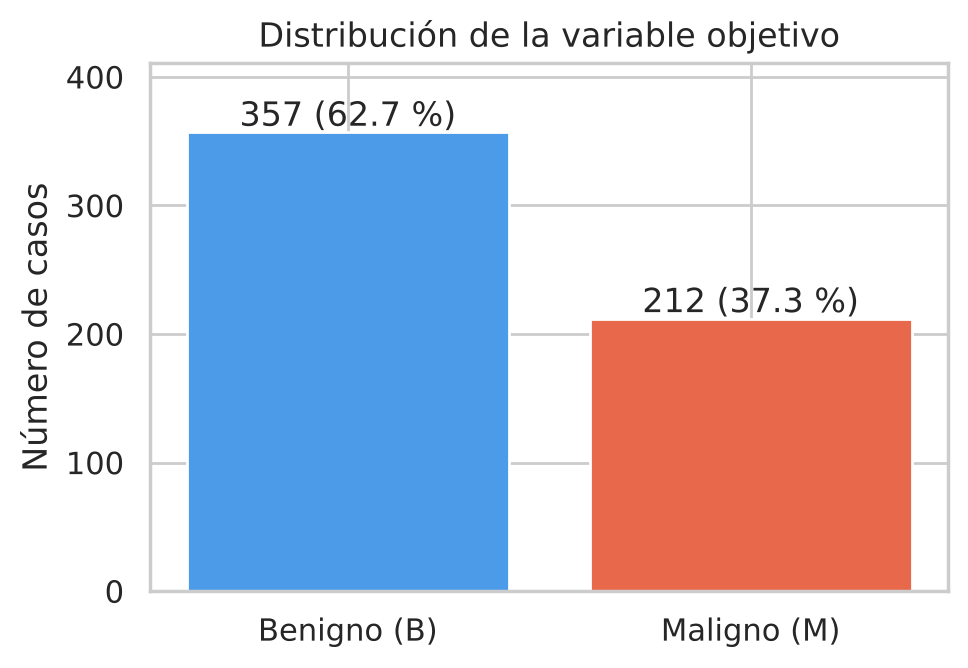

In [8]:
conteo = df["diagnosis"].map({"B": "Benigno (B)", "M": "Maligno (M)"}).value_counts()
porc = (conteo / conteo.sum() * 100).round(1)
display(pd.DataFrame({"casos": conteo, "%": porc}))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(conteo.index, conteo.values, color=["#4C9BE8", "#E8684C"])
for i, (n, p) in enumerate(zip(conteo.values, porc.values)):
    ax.text(i, n + 5, f"{n} ({p} %)", ha="center")
ax.set_ylabel("Número de casos"); ax.set_title("Distribución de la variable objetivo")
ax.set_ylim(0, conteo.max() * 1.15)
plt.tight_layout(); plt.show()

Hay **357 benignos (62,7 %) y 212 malignos (37,3 %)**. El desbalance es moderado, así que **no hace falta remuestrear**, pero sí hay que tenerlo en cuenta:
- Un modelo que dijera siempre "benigno" acertaría el 62,7 % → la *accuracy* sola es engañosa.
- La partición y la validación cruzada deben ser **estratificadas** para mantener esa proporción en cada subconjunto.

### 3.2 ¿Qué variables separan mejor las clases?

Como hay 30 variables, primero se mide cuánto separa cada una las clases con la **diferencia estandarizada de medias** (d de Cohen): cuanto mayor, más distintas son las distribuciones de B y M.

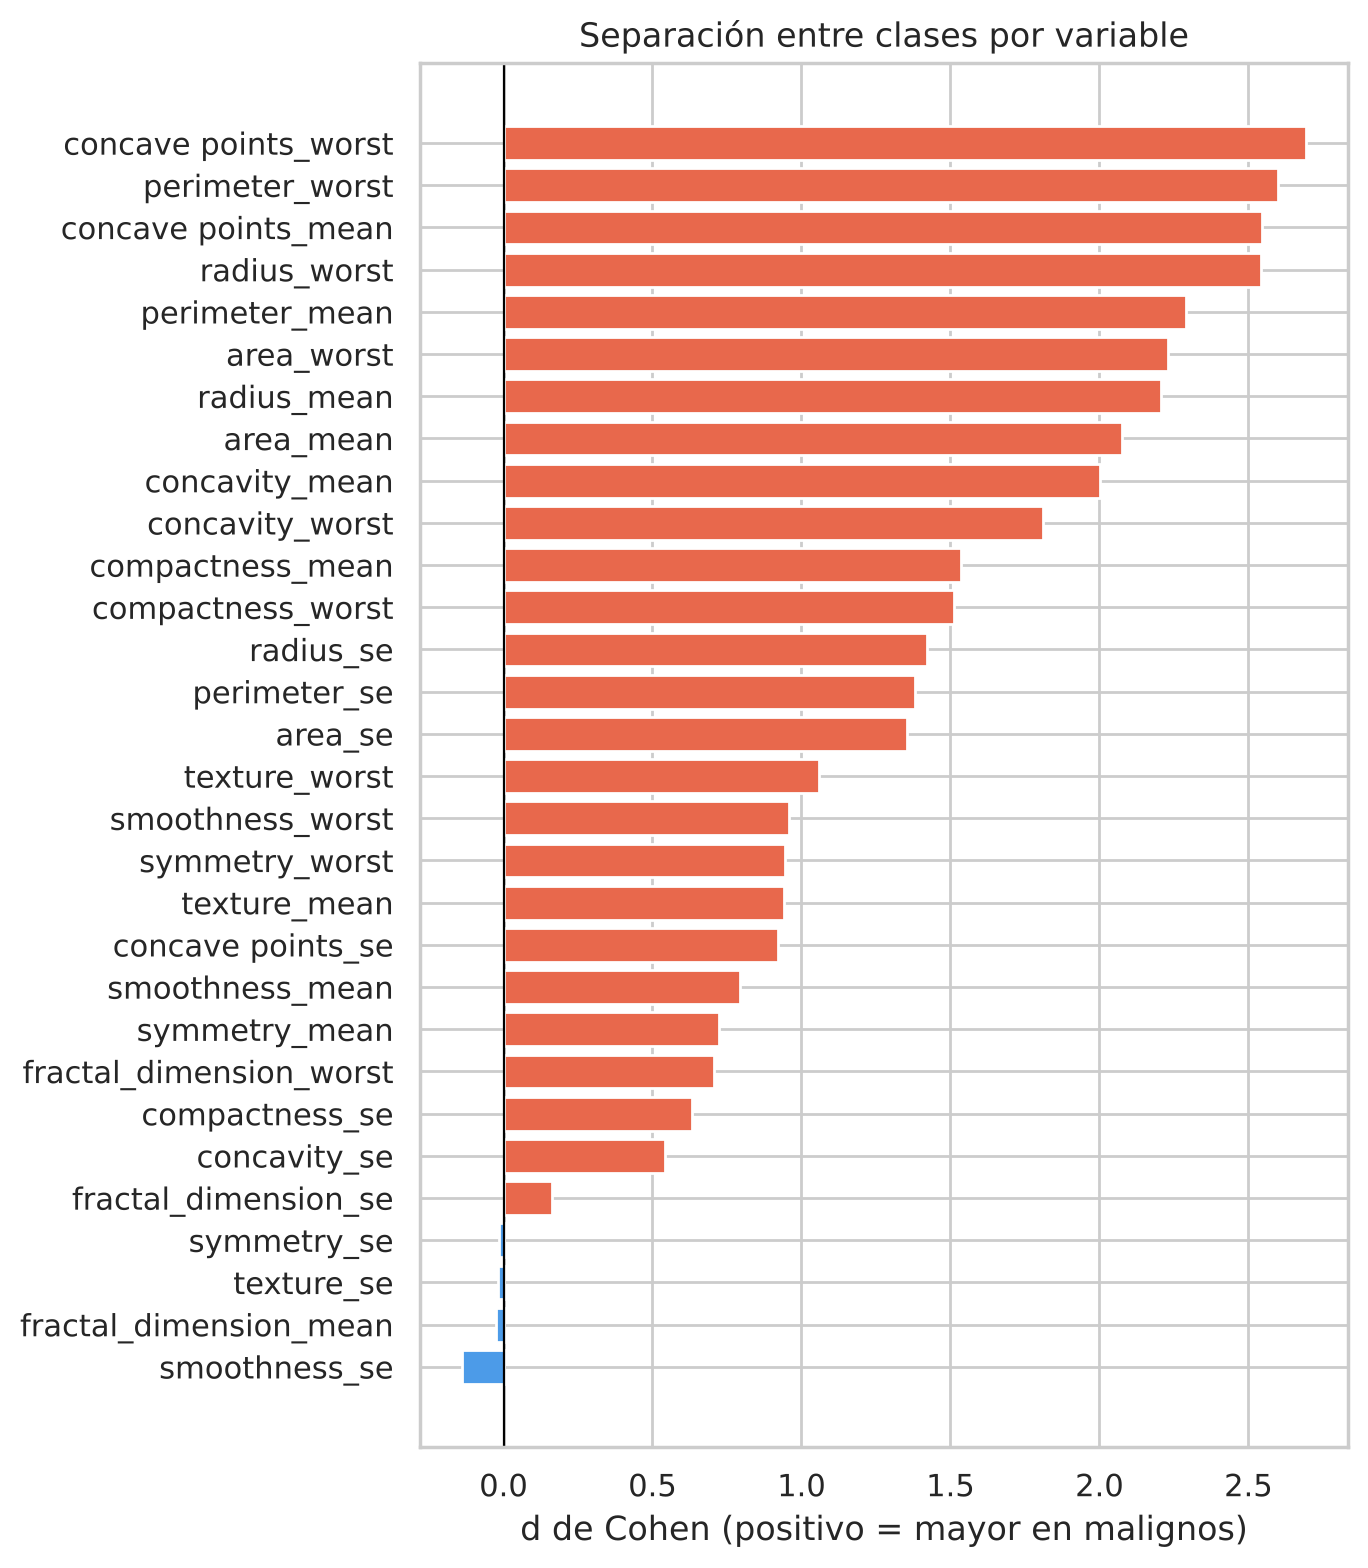

Las 5 variables que más separan:
 concave points_worst   2.690
perimeter_worst        2.600
concave points_mean    2.550
radius_worst           2.540
perimeter_mean         2.290


In [9]:
def cohen_d(col):
    m, b = X.loc[y == 1, col], X.loc[y == 0, col]
    s = np.sqrt(((len(m) - 1) * m.var() + (len(b) - 1) * b.var()) / (len(m) + len(b) - 2))
    return (m.mean() - b.mean()) / s

d = pd.Series({c: cohen_d(c) for c in features}).sort_values()

fig, ax = plt.subplots(figsize=(7, 8))
colores = ["#E8684C" if v > 0 else "#4C9BE8" for v in d.values]
ax.barh(d.index, d.values, color=colores)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("d de Cohen (positivo = mayor en malignos)")
ax.set_title("Separación entre clases por variable")
plt.tight_layout(); plt.show()

print("Las 5 variables que más separan:\n", d.abs().sort_values(ascending=False).head(5).round(2).to_string())

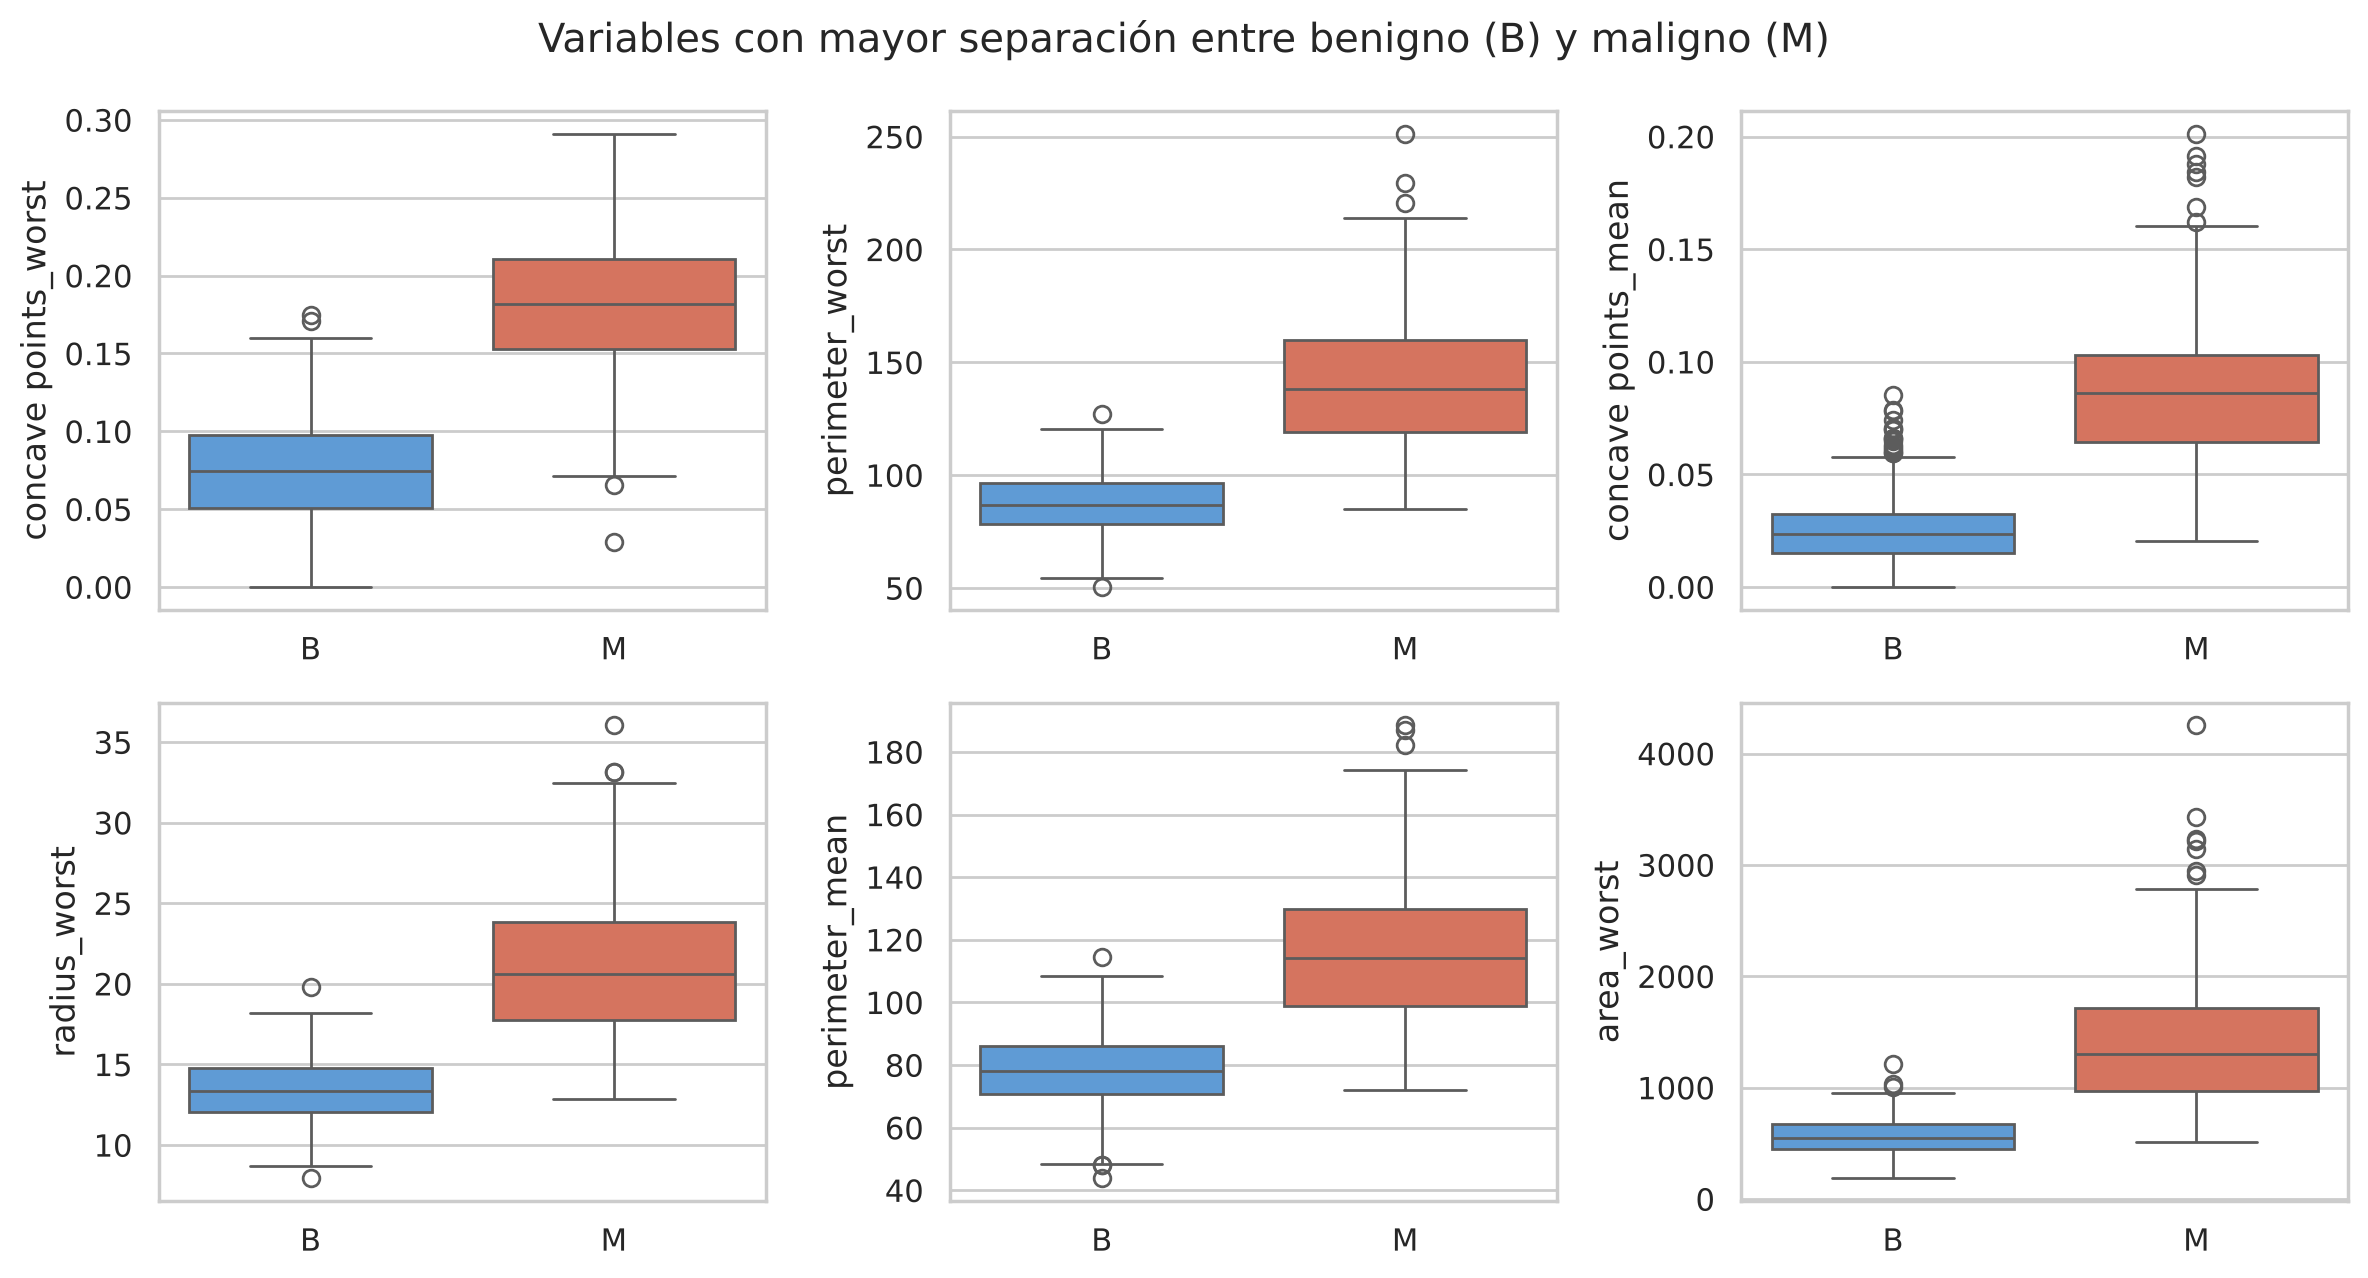

In [10]:
top = d.abs().sort_values(ascending=False).index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, col in zip(axes.ravel(), top):
    sns.boxplot(data=df, x="diagnosis", y=col, order=["B", "M"], ax=ax,
                palette={"B": "#4C9BE8", "M": "#E8684C"})
    ax.set_xlabel("")
fig.suptitle("Variables con mayor separación entre benigno (B) y maligno (M)")
plt.tight_layout(); plt.show()

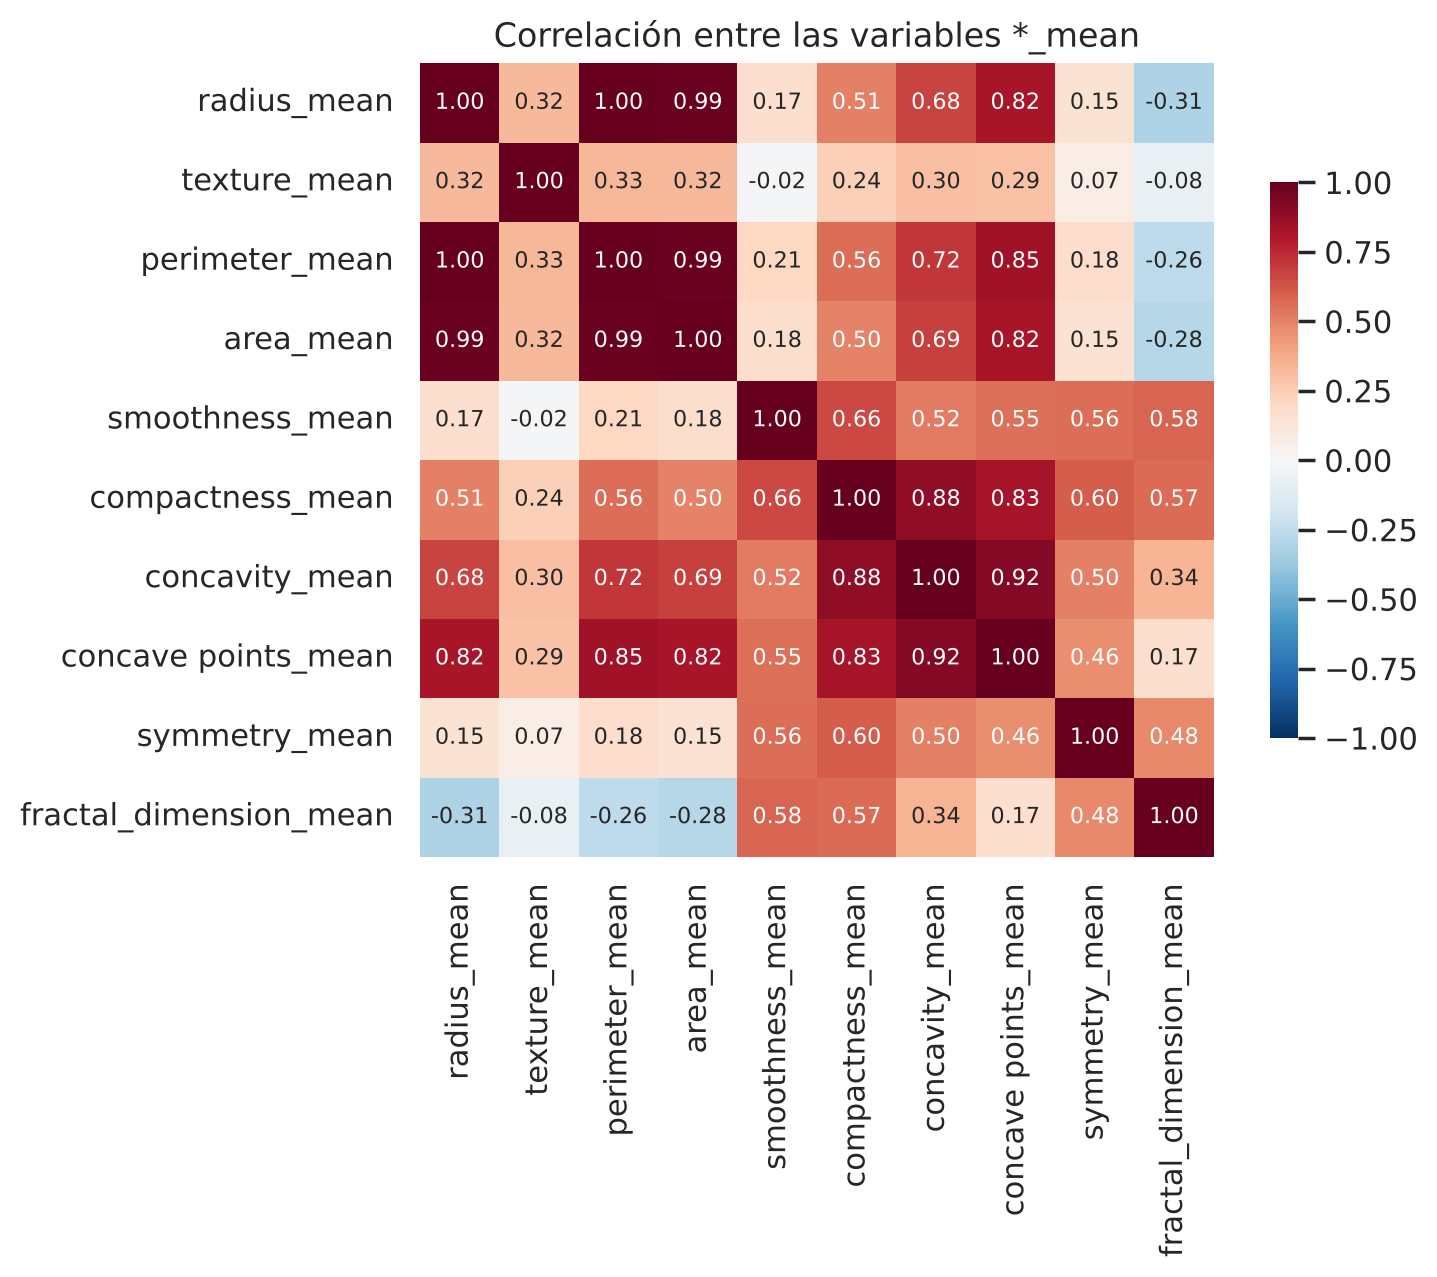

Pares de variables con |r| > 0.95: 15
radius_mean     perimeter_mean    0.998
radius_worst    perimeter_worst   0.994
radius_mean     area_mean         0.987
perimeter_mean  area_mean         0.987
radius_worst    area_worst        0.984


In [11]:
mean_cols = [c for c in features if c.endswith("_mean")]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(X[mean_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": .7}, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlación entre las variables *_mean")
plt.tight_layout(); plt.show()

corr = X.corr().abs()
pares = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().sort_values(ascending=False))
print("Pares de variables con |r| > 0.95:", (pares > 0.95).sum())
print(pares.head(5).round(3).to_string())

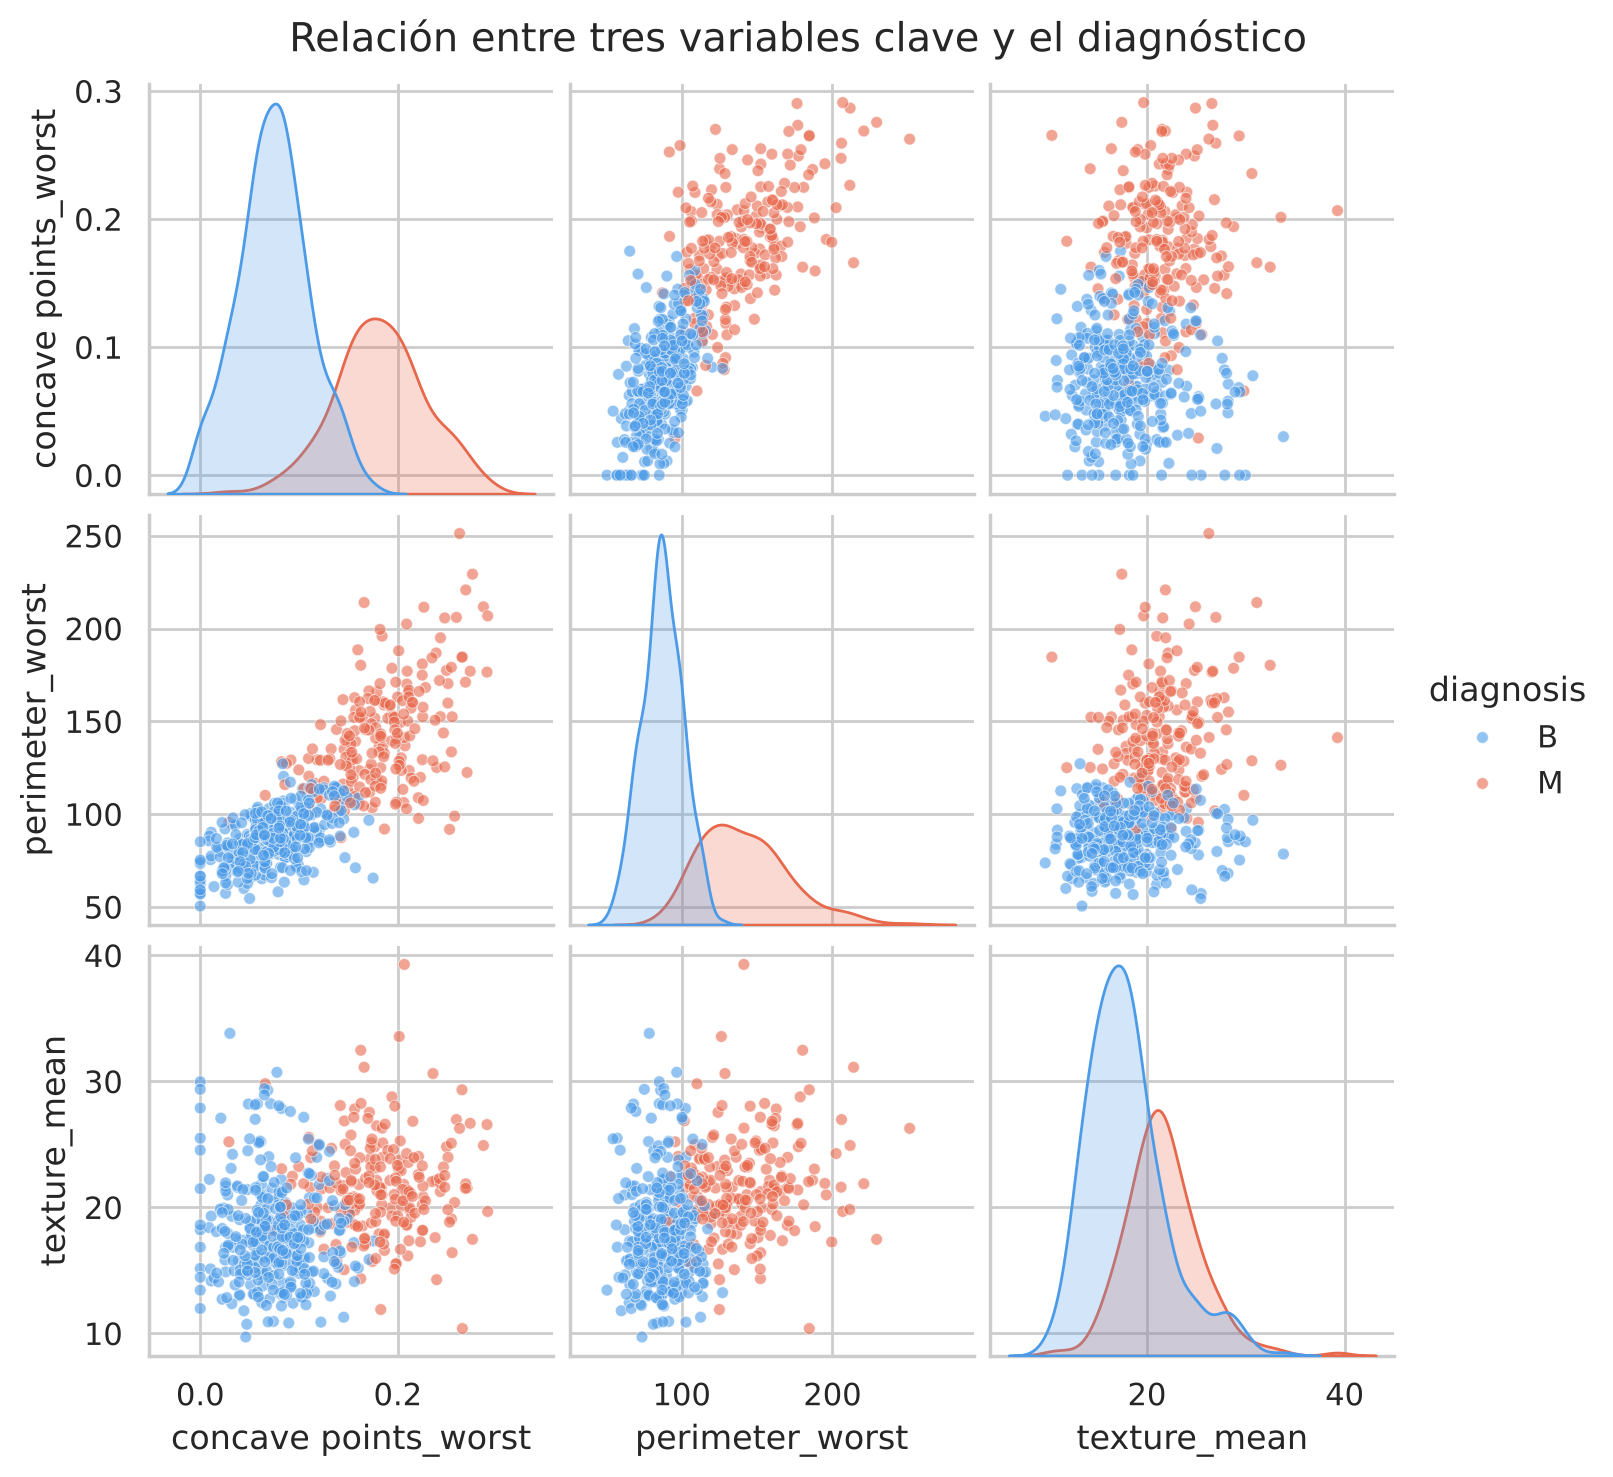

In [12]:
sns.pairplot(df[["diagnosis", "concave points_worst", "perimeter_worst", "texture_mean"]],
             hue="diagnosis", hue_order=["B", "M"], palette={"B": "#4C9BE8", "M": "#E8684C"},
             plot_kws={"alpha": .6, "s": 18}, height=2.4)
plt.suptitle("Relación entre tres variables clave y el diagnóstico", y=1.02)
plt.show()

**Hallazgos del EDA**
- Las variables de **tamaño** (radio, perímetro, área) y de **forma irregular** (concavidad, puntos cóncavos) son claramente mayores en los tumores malignos; las de peor valor (`_worst`) y media (`_mean`) separan más que los errores estándar (`_se`).
- Algunas variables casi no separan las clases (p. ej. `fractal_dimension_mean`, `smoothness_se`, `texture_se`).
- Hay **fuerte multicolinealidad**: radio, perímetro y área están correlacionados casi perfectamente (|r| ≈ 0,99), porque se calculan uno a partir del otro. Esto no afecta a los árboles, pero en la regresión logística hace inestables los coeficientes; por eso se usa **regularización** (la L2 que trae por defecto) en lugar de eliminar variables a mano.
- Las escalas son muy diferentes (`area_worst` llega a miles, `smoothness_mean` ronda 0,1). **KNN** se basa en distancias y la **regresión logística** con regularización también depende de la escala → hay que **estandarizar** para esos dos modelos.
- En el diagrama de pares, las clases se separan bastante bien con pocas variables, así que es razonable esperar un rendimiento alto.

## 4. Preparación y estrategia de validación

1. **Partición entrenamiento/prueba 80/20 estratificada** (`random_state=42`). El 20 % de prueba (114 casos) **no se toca** hasta la evaluación final.
2. **Pipelines**: el `StandardScaler` va *dentro* del pipeline de LR y KNN. Así, en cada pliegue de validación el escalador se ajusta **solo con los datos de entrenamiento de ese pliegue**, evitando fuga de información. Los árboles y el bosque no necesitan escalado (dividen por umbrales de cada variable).
3. **Validación cruzada estratificada de 5 pliegues** sobre el entrenamiento (con los mismos pliegues para todos los modelos) para comparar y ajustar hiperparámetros.

**Métricas** (clase positiva = maligno):
- **Recall (sensibilidad)**: de los tumores malignos, ¿cuántos detecta? Es la **métrica prioritaria**, porque un falso negativo es el error más grave.
- **Precisión**: de los que el modelo llama malignos, ¿cuántos lo son?
- **F1**: equilibrio entre precisión y recall; se usa para **elegir hiperparámetros**.
- **Exactitud balanceada** y **ROC-AUC**: no se dejan engañar por el desbalance. La *accuracy* se reporta solo como referencia.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print(f"Entrenamiento: {X_train.shape[0]} casos | % malignos = {y_train.mean()*100:.1f}")
print(f"Prueba:        {X_test.shape[0]} casos | % malignos = {y_test.mean()*100:.1f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"accuracy": "accuracy", "balanced_acc": "balanced_accuracy",
           "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

Entrenamiento: 455 casos | % malignos = 37.4
Prueba:        114 casos | % malignos = 36.8


## 5. Modelos

### 5.1 Comparación inicial con hiperparámetros por defecto

In [14]:
modelos = {
    "Regresión logística": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=5000, random_state=SEED))]),
    "KNN": Pipeline([("scaler", StandardScaler()),
                     ("clf", KNeighborsClassifier())]),
    "Árbol de decisión": Pipeline([("clf", DecisionTreeClassifier(random_state=SEED))]),
    "Bosque aleatorio": Pipeline([("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
}

def tabla_cv(dic_modelos):
    filas = {}
    for nombre, m in dic_modelos.items():
        r = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
        filas[nombre] = {f"{k}": f"{r['test_'+k].mean():.3f} ± {r['test_'+k].std():.3f}" for k in scoring}
    return pd.DataFrame(filas).T

tabla_base = tabla_cv(modelos)
tabla_base

,accuracy,balanced_acc,precision,recall,f1,roc_auc
Regresión logística,0.974 ± 0.015,0.969 ± 0.019,0.977 ± 0.028,0.953 ± 0.040,0.964 ± 0.021,0.996 ± 0.005
KNN,0.965 ± 0.019,0.955 ± 0.022,0.988 ± 0.025,0.918 ± 0.034,0.951 ± 0.026,0.987 ± 0.014
Árbol de decisión,0.923 ± 0.033,0.917 ± 0.038,0.900 ± 0.041,0.894 ± 0.061,0.896 ± 0.045,0.917 ± 0.038
Bosque aleatorio,0.965 ± 0.015,0.960 ± 0.020,0.964 ± 0.011,0.941 ± 0.042,0.952 ± 0.021,0.989 ± 0.007


### 5.2 Ajuste de hiperparámetros

Con `GridSearchCV`, usando **los mismos 5 pliegues** y **F1** como criterio. Se exploran pocos valores, elegidos por lo que controla cada hiperparámetro:
- **Regresión logística**: `C` (inverso de la regularización) y `class_weight` (dar más peso a la clase minoritaria).
- **KNN**: número de vecinos `k` y si los vecinos más cercanos pesan más (`weights`).
- **Árbol**: profundidad máxima y mínimo de casos por hoja (controlan el sobreajuste).
- **Bosque**: número de árboles, variables por división y mínimo de casos por hoja.

In [15]:
grids = {
    "Regresión logística": {"clf__C": [0.01, 0.1, 1, 10, 100], "clf__class_weight": [None, "balanced"]},
    "KNN": {"clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21], "clf__weights": ["uniform", "distance"]},
    "Árbol de decisión": {"clf__max_depth": [2, 3, 4, 5, 6, None], "clf__min_samples_leaf": [1, 3, 5, 10],
                          "clf__class_weight": [None, "balanced"]},
    "Bosque aleatorio": {"clf__n_estimators": [200, 500], "clf__max_features": ["sqrt", 0.3],
                         "clf__min_samples_leaf": [1, 3], "clf__class_weight": [None, "balanced"]},
}

mejores, filas = {}, []
for nombre, m in modelos.items():
    gs = GridSearchCV(m, grids[nombre], cv=cv, scoring="f1", n_jobs=-1)
    gs.fit(X_train, y_train)
    mejores[nombre] = gs.best_estimator_
    params = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    filas.append({"Modelo": nombre, "Mejores hiperparámetros": params, "F1 (CV)": round(gs.best_score_, 3)})

pd.set_option("display.max_colwidth", None)
pd.DataFrame(filas).set_index("Modelo")

,Mejores hiperparámetros,F1 (CV)
Modelo,,
Regresión logística,"{'C': 0.1, 'class_weight': 'balanced'}",0.967
KNN,"{'n_neighbors': 3, 'weights': 'uniform'}",0.963
Árbol de decisión,"{'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 5}",0.938
Bosque aleatorio,"{'class_weight': None, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 200}",0.961


In [16]:
tabla_ajustada = tabla_cv(mejores)
print("Validación cruzada (5 pliegues, media ± desv. estándar) con los modelos ajustados:")
tabla_ajustada

Validación cruzada (5 pliegues, media ± desv. estándar) con los modelos ajustados:


,accuracy,balanced_acc,precision,recall,f1,roc_auc
Regresión logística,0.976 ± 0.008,0.971 ± 0.010,0.983 ± 0.023,0.953 ± 0.024,0.967 ± 0.011,0.995 ± 0.005
KNN,0.974 ± 0.018,0.966 ± 0.022,0.994 ± 0.013,0.935 ± 0.039,0.963 ± 0.025,0.989 ± 0.013
Árbol de decisión,0.954 ± 0.022,0.949 ± 0.023,0.949 ± 0.046,0.929 ± 0.040,0.938 ± 0.030,0.974 ± 0.015
Bosque aleatorio,0.971 ± 0.016,0.967 ± 0.019,0.976 ± 0.022,0.947 ± 0.034,0.961 ± 0.022,0.988 ± 0.009


## 6. Evaluación final en el conjunto de prueba

Cada modelo ajustado se reentrena con **todo** el entrenamiento y se evalúa **una sola vez** en el 20 % reservado.

In [17]:
res_test, preds, probas = {}, {}, {}
for nombre, m in mejores.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    pr = m.predict_proba(X_test)[:, 1]
    preds[nombre], probas[nombre] = p, pr
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    res_test[nombre] = {
        "Accuracy": accuracy_score(y_test, p),
        "Exactitud balanceada": balanced_accuracy_score(y_test, p),
        "Precisión (M)": precision_score(y_test, p),
        "Recall (M)": recall_score(y_test, p),
        "F1 (M)": f1_score(y_test, p),
        "ROC-AUC": roc_auc_score(y_test, pr),
        "Falsos negativos": fn, "Falsos positivos": fp,
    }

tabla_test = pd.DataFrame(res_test).T.sort_values(["F1 (M)", "Recall (M)"], ascending=False)
tabla_test[["Falsos negativos", "Falsos positivos"]] = tabla_test[["Falsos negativos", "Falsos positivos"]].astype(int)
tabla_test.round(3)

,Accuracy,Exactitud balanceada,Precisión (M),Recall (M),F1 (M),ROC-AUC,Falsos negativos,Falsos positivos
Regresión logística,0.991,0.988,1.000,0.976,0.988,0.998,1,0
Bosque aleatorio,0.974,0.964,1.000,0.929,0.963,0.993,3,0
KNN,0.939,0.922,0.973,0.857,0.911,0.982,6,1
Árbol de decisión,0.904,0.889,0.897,0.833,0.864,0.908,7,4


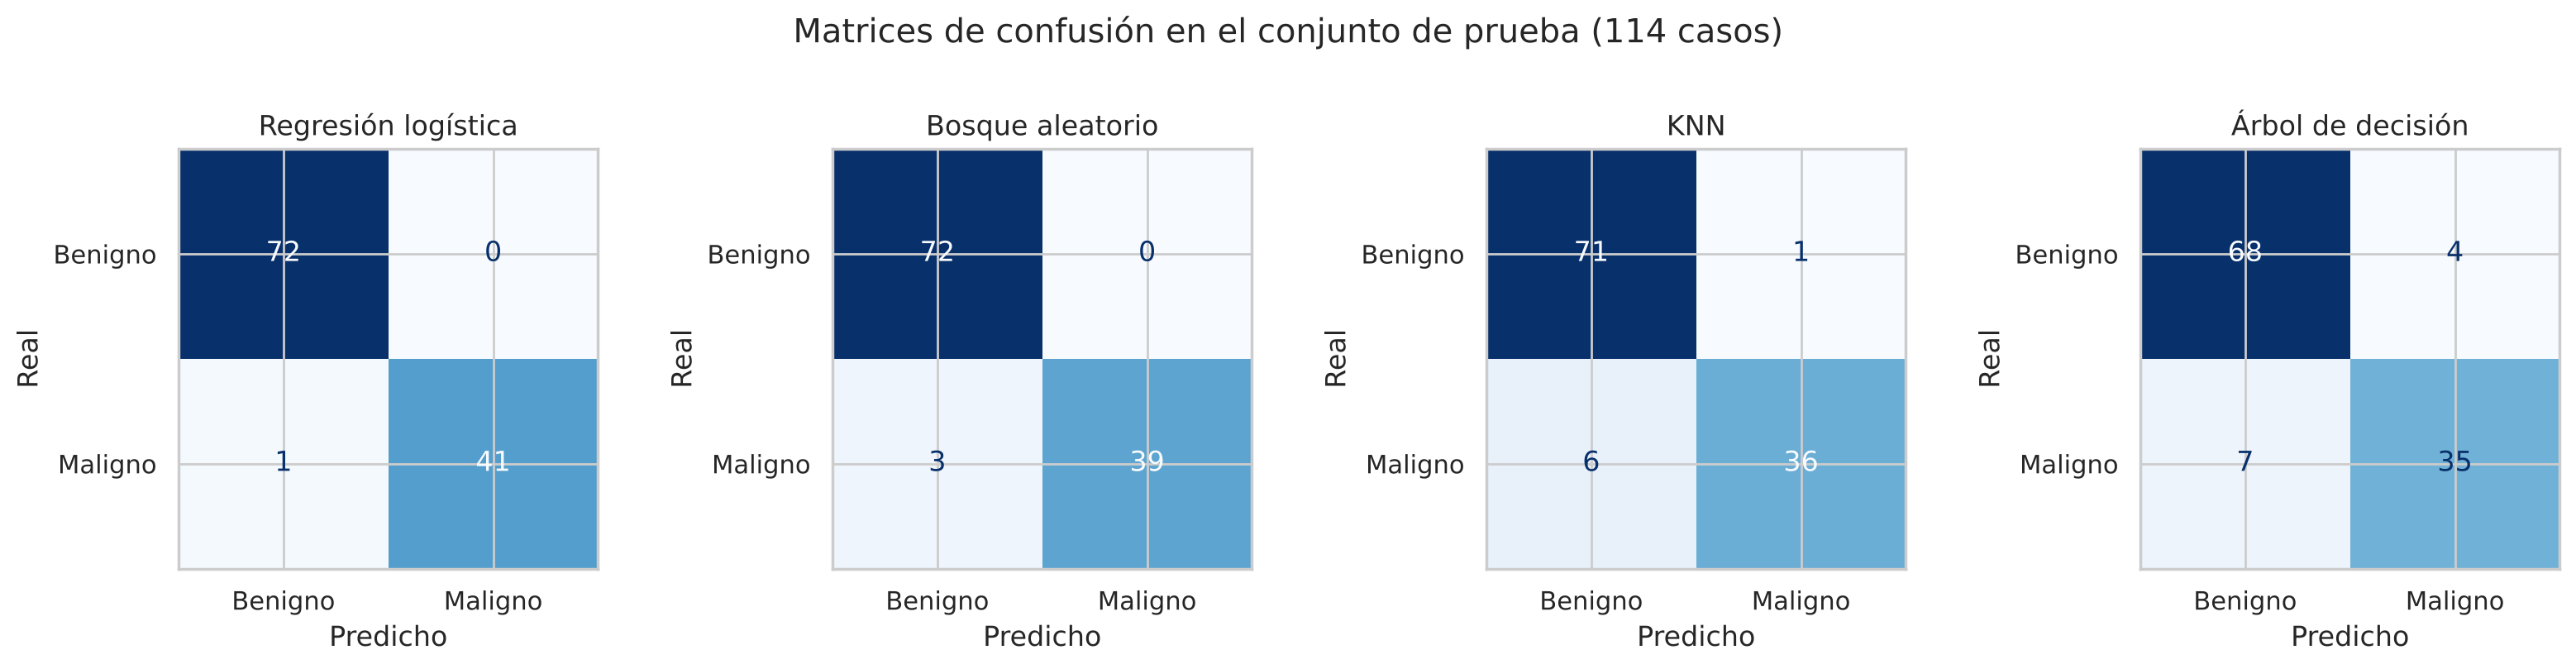

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, nombre in zip(axes, tabla_test.index):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[nombre]),
                           display_labels=["Benigno", "Maligno"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre); ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
plt.suptitle("Matrices de confusión en el conjunto de prueba (114 casos)", y=1.03)
plt.tight_layout(); plt.show()

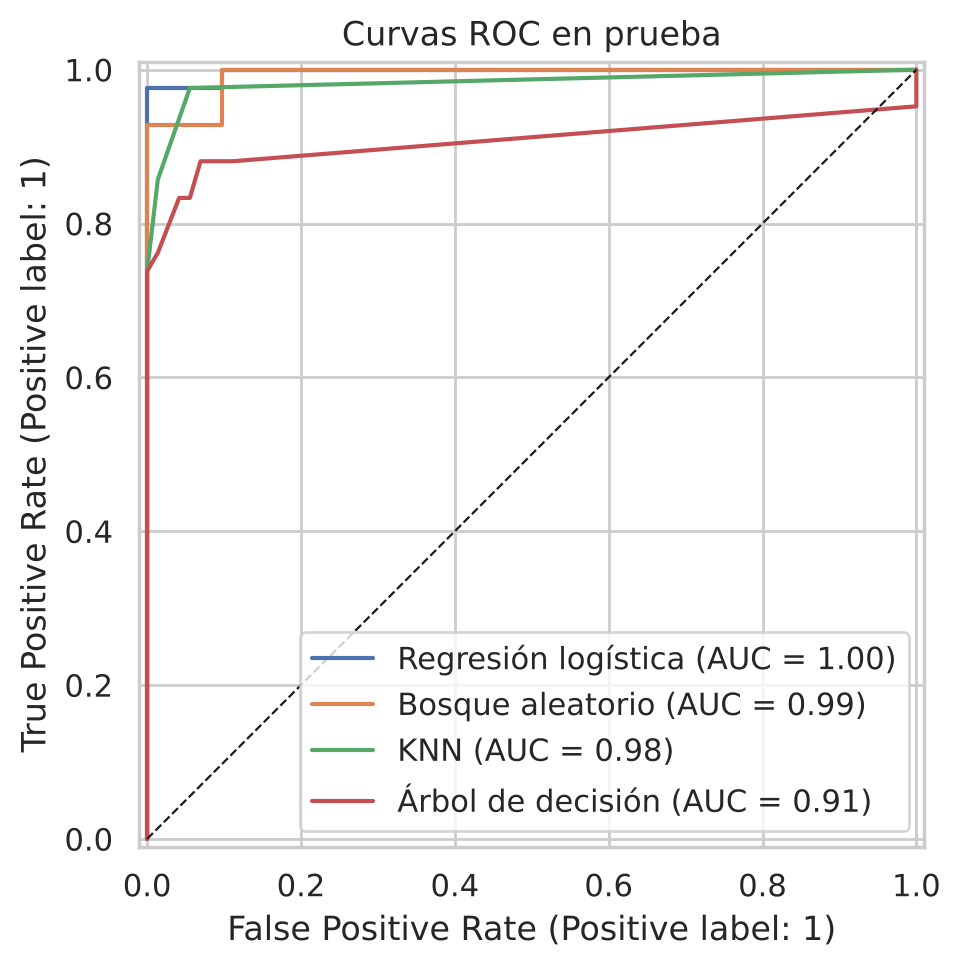

In [19]:
from sklearn.metrics import RocCurveDisplay
fig, ax = plt.subplots(figsize=(5.5, 5))
for nombre in tabla_test.index:
    RocCurveDisplay.from_predictions(y_test, probas[nombre], name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_title("Curvas ROC en prueba")
plt.tight_layout(); plt.show()

## 7. Análisis de errores del mejor modelo

In [20]:
mejor = tabla_test.index[0]
print("Mejor modelo según F1 en prueba:", mejor)
print(classification_report(y_test, preds[mejor], target_names=["Benigno", "Maligno"], digits=3))

errores = X_test.assign(real=y_test.map({0: "B", 1: "M"}),
                        predicho=pd.Series(preds[mejor], index=X_test.index).map({0: "B", 1: "M"}),
                        prob_maligno=probas[mejor])
errores = errores[errores["real"] != errores["predicho"]]
errores["tipo"] = np.where(errores["real"] == "M", "Falso negativo", "Falso positivo")
errores[["tipo", "real", "predicho", "prob_maligno"] + top[:4]].round(3)

Mejor modelo según F1 en prueba: Regresión logística
              precision    recall  f1-score   support

     Benigno      0.986     1.000     0.993        72
     Maligno      1.000     0.976     0.988        42

    accuracy                          0.991       114
   macro avg      0.993     0.988     0.991       114
weighted avg      0.991     0.991     0.991       114



,tipo,real,predicho,prob_maligno,concave points_worst,perimeter_worst,concave points_mean,radius_worst
73,Falso negativo,M,B,0.216,0.138,110.300,0.051,16.570


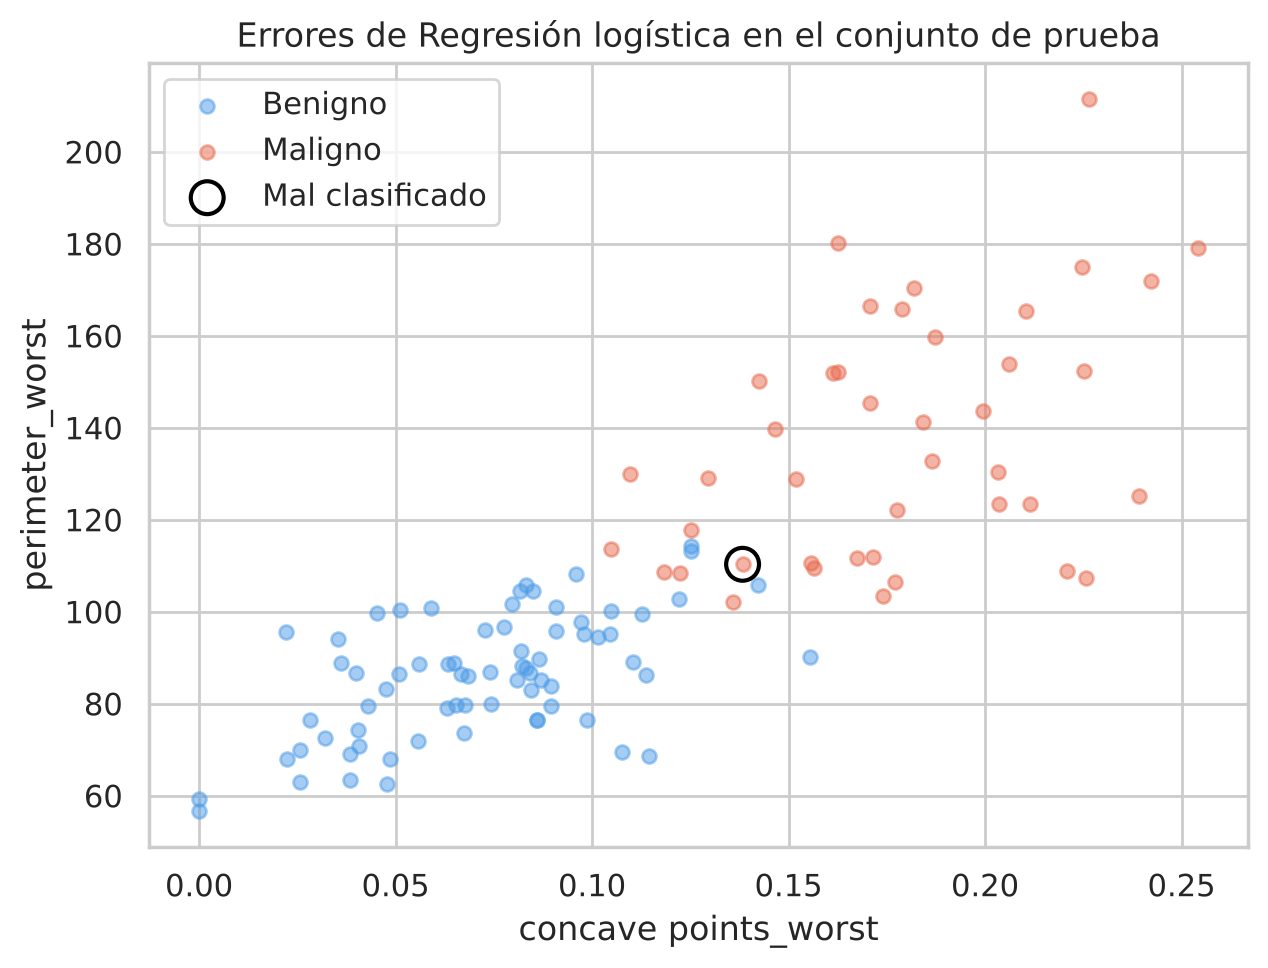

Valores medianos en entrenamiento por clase, como referencia:


,concave points_worst,perimeter_worst
diagnosis,,
B,0.074,87.000
M,0.183,139.350


In [21]:
# ¿Dónde caen los errores respecto a la nube de casos? Se usan las dos variables que más separan.
vx, vy = "concave points_worst", "perimeter_worst"
fig, ax = plt.subplots(figsize=(6.5, 5))
for clase, color in [(0, "#4C9BE8"), (1, "#E8684C")]:
    sub = X_test[y_test == clase]
    ax.scatter(sub[vx], sub[vy], c=color, alpha=.5, s=25, label=["Benigno", "Maligno"][clase])
ax.scatter(errores[vx], errores[vy], facecolors="none", edgecolors="black", s=140, lw=1.5, label="Mal clasificado")
ax.set_xlabel(vx); ax.set_ylabel(vy); ax.legend()
ax.set_title(f"Errores de {mejor} en el conjunto de prueba")
plt.tight_layout(); plt.show()

print("Valores medianos en entrenamiento por clase, como referencia:")
display(X_train.groupby(y_train)[[vx, vy]].median().rename(index={0: "B", 1: "M"}).round(3))

### 7.1 ¿Se pueden reducir los falsos negativos? Ajuste del umbral

Por defecto se predice "maligno" si la probabilidad es ≥ 0,5. En un contexto de cribado puede preferirse un umbral más bajo. Para no hacer trampa, el umbral se elige **solo con el entrenamiento** (probabilidades obtenidas por validación cruzada) y después se comprueba una vez en prueba.

In [22]:
modelo_mejor = mejores[mejor]
oof = cross_val_predict(modelo_mejor, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

umbrales = np.round(np.arange(0.10, 0.55, 0.05), 2)
tabla_umbral = pd.DataFrame([{
    "umbral": u,
    "recall (CV)": recall_score(y_train, oof >= u),
    "precisión (CV)": precision_score(y_train, oof >= u),
    "F1 (CV)": f1_score(y_train, oof >= u)} for u in umbrales]).set_index("umbral")
display(tabla_umbral.round(3))

# Umbral más alto que logra recall >= 0.98 en validación cruzada
candidatos = tabla_umbral[tabla_umbral["recall (CV)"] >= 0.98]
u_sel = candidatos.index.max() if len(candidatos) else 0.5
p_u = (probas[mejor] >= u_sel).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, p_u).ravel()
print(f"Umbral elegido con entrenamiento: {u_sel}")
print(f"En prueba -> recall = {recall_score(y_test, p_u):.3f}, precisión = {precision_score(y_test, p_u):.3f}, "
      f"falsos negativos = {fn}, falsos positivos = {fp}")

,recall (CV),precisión (CV),F1 (CV)
umbral,,,
0.100,0.994,0.707,0.826
0.150,0.994,0.761,0.862
0.200,0.994,0.824,0.901
0.250,0.982,0.874,0.925
0.300,0.982,0.913,0.946
0.350,0.976,0.938,0.957
0.400,0.976,0.943,0.960
0.450,0.965,0.965,0.965
0.500,0.953,0.982,0.967


Umbral elegido con entrenamiento: 0.3
En prueba -> recall = 0.976, precisión = 0.891, falsos negativos = 1, falsos positivos = 5


### 7.2 ¿En qué se fijan los modelos?

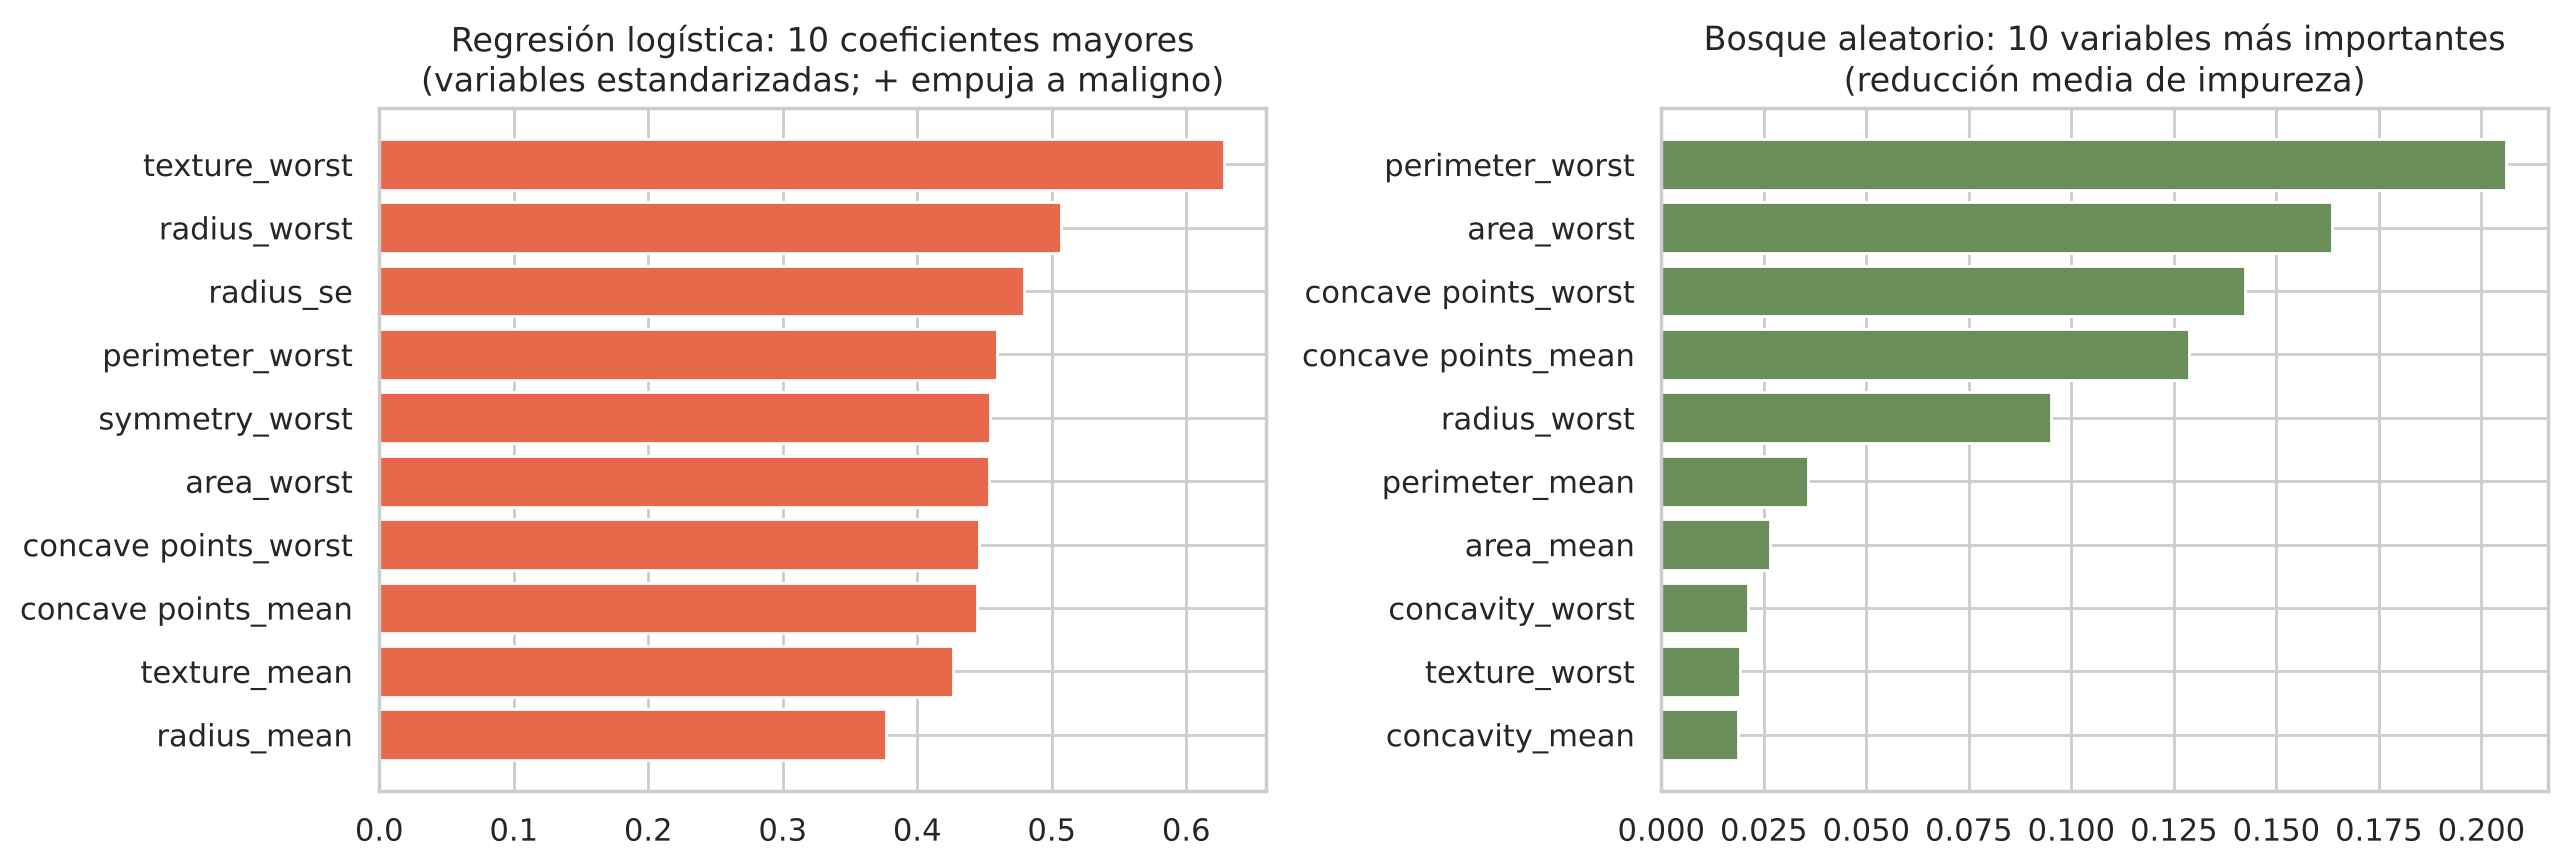

In [23]:
lr = mejores["Regresión logística"].named_steps["clf"]
rf = mejores["Bosque aleatorio"].named_steps["clf"]
coef = pd.Series(lr.coef_[0], index=features).sort_values(key=abs, ascending=False).head(10)[::-1]
imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False).head(10)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(coef.index, coef.values, color=["#E8684C" if v > 0 else "#4C9BE8" for v in coef.values])
axes[0].set_title("Regresión logística: 10 coeficientes mayores\n(variables estandarizadas; + empuja a maligno)")
axes[1].barh(imp.index, imp.values, color="#6A8E5A")
axes[1].set_title("Bosque aleatorio: 10 variables más importantes\n(reducción media de impureza)")
plt.tight_layout(); plt.show()

## 8. Conclusiones

**Tabla resumen** (la tabla completa de prueba está en la sección 6):

| Modelo | F1 en CV (5 pliegues) | Recall M en prueba | Precisión M en prueba | Falsos negativos / positivos (prueba) |
|---|---|---|---|---|
| **Regresión logística** | **0,967 ± 0,011** | **0,976** | **1,000** | **1 / 0** |
| Bosque aleatorio | 0,961 ± 0,022 | 0,929 | 1,000 | 3 / 0 |
| KNN | 0,963 ± 0,025 | 0,857 | 0,973 | 6 / 1 |
| Árbol de decisión | 0,938 ± 0,030 | 0,833 | 0,897 | 7 / 4 |

**¿Qué modelo funcionó mejor?** La **regresión logística** (estandarizada, `C = 0,1`, `class_weight="balanced"`). Fue la mejor en validación cruzada y en prueba: un solo error en 114 casos y ROC-AUC de 0,998. Tiene sentido por lo visto en el EDA: las clases se separan casi linealmente con las variables de tamaño y concavidad. La regularización fuerte (`C` pequeño) controla la multicolinealidad entre radio, perímetro y área, y el peso balanceado empuja el modelo a detectar más malignos. Además, sus coeficientes se pueden interpretar: la textura, el radio y el perímetro en su peor valor son los que más empujan hacia "maligno". Coinciden en buena parte con las variables más importantes del bosque aleatorio (perímetro, área y puntos cóncavos en su peor valor), aunque la regresión logística le da más peso a la textura.

**¿Qué errores comete?** Un **falso negativo**: un tumor maligno al que el modelo da solo un 22 % de probabilidad de malignidad. En el gráfico de errores cae en la zona de solapamiento: valores de concavidad y perímetro intermedios, entre la mediana de benignos y la de malignos. Es un caso límite, no un error de datos. Cometió **cero falsos positivos**. Si se baja el umbral a 0,30 (elegido solo con el entrenamiento para lograr un recall ≥ 0,98), **ese caso sigue sin detectarse** y aparecen 5 falsos positivos. Bajar el umbral no lo corrige; para ese caso haría falta otra información, como pruebas clínicas adicionales.

**Comparación entre modelos**
- El **bosque aleatorio** queda muy cerca y tampoco da falsos positivos, pero deja escapar 3 malignos.
- **KNN** tuvo buen F1 en validación cruzada (0,963), pero en prueba falló 6 malignos. Con solo 42 malignos en prueba, cada error baja el recall unos 2,4 puntos, así que el resultado de una sola partición varía mucho. Por eso la media y la desviación de la validación cruzada son la referencia principal para comparar.
- El **árbol de decisión** individual es el más inestable (mayor desviación en CV) y el peor en prueba, como era de esperar de un solo árbol frente a un conjunto de ellos.

**Justificación de las decisiones**
- *Limpieza*: solo se eliminaron `id` y la columna vacía. No había faltantes ni duplicados. Los ceros en concavidad son reales y se conservaron, igual que los valores extremos, que son biológicamente plausibles e informativos.
- *Preparación*: `diagnosis` se codificó con maligno = 1 para que las métricas se calculen sobre la clase que importa detectar. El escalado se aplicó solo a LR y KNN, dentro de un `Pipeline`, para que se ajuste únicamente con datos de entrenamiento.
- *Validación*: partición 80/20 estratificada y validación cruzada estratificada de 5 pliegues, con los mismos pliegues para todos los modelos. Los hiperparámetros se eligieron por F1 y el conjunto de prueba se usó una sola vez.
- *Métricas*: se priorizó el **recall de malignos**, junto con F1, exactitud balanceada y ROC-AUC, porque las clases están desbalanceadas y un falso negativo es el error más costoso.

**Limitaciones**: el conjunto de prueba es pequeño (114 casos). El resultado de la regresión logística en prueba (F1 = 0,988) es algo mejor que su media en CV (0,967), en parte por la partición concreta. Lo más prudente es esperar un rendimiento cercano al de la validación cruzada: ~97 % de exactitud y ~95 % de recall. Es un ejercicio académico y no reemplaza un diagnóstico médico.

## 9. Uso de LLMs

*(Texto para adaptar a lo que realmente hiciste.)*

Se usó un asistente de IA (Claude, de Anthropic) como apoyo para estructurar el notebook, proponer el código de los pipelines y redactar borradores de las explicaciones. Las decisiones se verificaron así:
- La necesidad de escalar para KNN y regresión logística, y el uso de `Pipeline` para evitar fuga de información, se contrastaron con la documentación de scikit-learn (*Preprocessing data* y *Common pitfalls*).
- La validación cruzada estratificada y las métricas (recall, F1, `balanced_accuracy`, ROC-AUC) se revisaron en las guías *Cross-validation* y *Classification metrics* de scikit-learn.
- Cada decisión de limpieza se respaldó con la salida del propio código (conteos de faltantes, duplicados y ceros), no con lo que dijo la IA.
- Todos los números de las conclusiones salen de las tablas generadas al ejecutar el notebook.